In [15]:
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

### LightGBM
Model ma się uczyć zależności między ilością przepompowanych ścieków, a opadami atmosferycznymi.
Nie tylko przewidywanie pompowania na podstawie poprzednich godzin, ale uwzględnienie jak to reagowało na deszcz

CEL: Wykrywanie sytuacji, w których ilość przepompowanych ścieków jest większa niż powinna być przy danych warunkach opadowych - czy powinniśmy się spodziewać aż tak dużej ilości ścieków?

LightGBM - ma wyznaczać oczekiwane pompowanie (na podtsaiwe historycznej zależności między opadami, porą dnia, ilością ścieków) i
ma wykrywać nadwyżki względem pogody

In [2]:
%load_ext autoreload
%autoreload 2


from przygotowanie_danych_przepompowania import przygotuj_dane_przepompowania_z_opadami

X_train, X_val, X_test, y_train, y_val, y_test = przygotuj_dane_przepompowania_z_opadami()

In [3]:


# Dwa modele LightGBM:
# 1. Pierwszy przewiduje typową ilość przepompowanych ścieków
# 2. Drugi wyznacza górną granicę oczekiwanego pompowania (Q97) - uwzględniając opady
# Przekroczenie Q97 wskazuje potencjalnie nietypowy dodatkowy dopływ

lgbm = LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05,
                     num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm.fit(X_train, y_train)

lgbm_q = LGBMRegressor(objective="quantile", alpha=0.97, n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_q.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,objective,'quantile'
,min_child_samples,40
,random_state,42
,alpha,0.97
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


In [4]:
y_pred_val = lgbm.predict(X_val)
q_val = lgbm_q.predict(X_val)

prof = y_train.groupby(y_train.index.hour).median()
base_val = prof.reindex(y_val.index.hour).values

print("MAE modelu:  ", round(mean_absolute_error(y_val, y_pred_val), 2))
print("MAE baseline:", round(mean_absolute_error(y_val, base_val), 2))

MAE modelu:   8.22
MAE baseline: 8.73


Godziny ponad normę: 47 z 2628


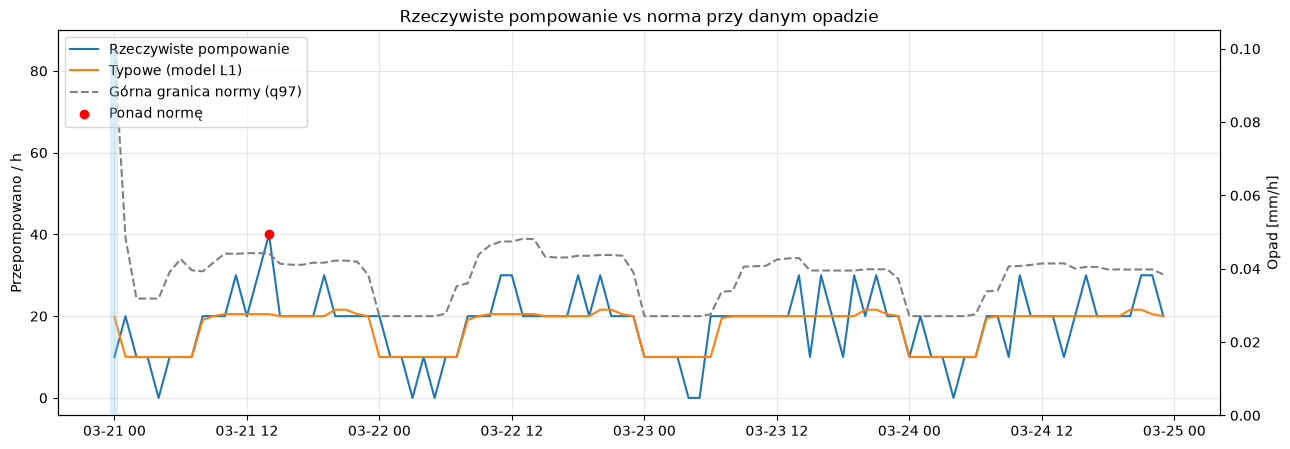

In [5]:
results_val = pd.DataFrame({
    "rzeczywiste": y_val,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_val["opad_0h"],
    "opad_6h": X_val["opad_6h"],
}, index=y_val.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-03-21":"2026-03-24"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [6]:
# Suma przekroczeń Q97 z ostatnich 6 godzin
results_val["ponad_6h"] = results_val["ponad_q97"].rolling(6, min_periods=6).sum()

# Duże przekroczenie w pojedynczej godzinie
results_val["alarm_pojedynczy"] = results_val["ponad_q97"] > 20

# Mniejsze przekroczenia skumulowane w 6 godzinach
results_val["alarm_skumulowany"] = results_val["ponad_6h"] > 80

# Końcowy alarm
results_val["alarm"] = results_val["alarm_pojedynczy"] | results_val["alarm_skumulowany"]

print("Alarmy pojedyncze:", results_val["alarm_pojedynczy"].sum())
print("Alarmy skumulowane:", results_val["alarm_skumulowany"].sum())

Alarmy pojedyncze: 23
Alarmy skumulowane: 43


# CATBOOST

In [7]:
# CATBOOST
from catboost import CatBoostRegressor

cb_median = CatBoostRegressor(
    loss_function = "MAE",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_median.fit(X_train, y_train)

cb_q97 = CatBoostRegressor(
    loss_function = "Quantile:alpha=0.97",
    iterations = 500,
    learning_rate = 0.05,
    depth = 5,
    random_seed=42,
    verbose=0
)
cb_q97.fit(X_train, y_train)

y_pred_val = cb_median.predict(X_val)
q_val = cb_q97.predict(X_val)

print("Odsetek przekroczeń Q97 (CatBoost):", round((y_val > q_val).mean() * 100, 2), "%")

Odsetek przekroczeń Q97 (CatBoost): 1.37 %


Godziny ponad normę: 36 z 2628


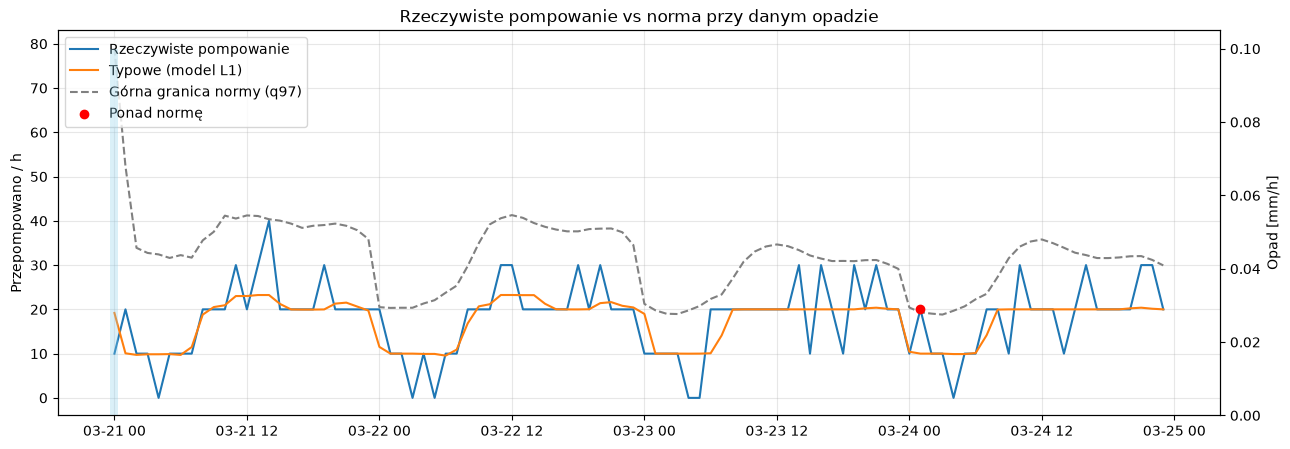

In [8]:
results_val = pd.DataFrame({
    "rzeczywiste": y_val,
    "prognoza": y_pred_val,
    "q97": q_val,
    "opad": X_val["opad_0h"],
    "opad_6h": X_val["opad_6h"],
}, index=y_val.index)

results_val["anomaly"] = results_val["rzeczywiste"] > results_val["q97"]
results_val["ponad_q97"] = (results_val["rzeczywiste"] - results_val["q97"]).clip(lower=0)

print("Godziny ponad normę:", int(results_val["anomaly"].sum()), "z", len(results_val))

sample = results_val.loc["2026-03-21":"2026-03-24"]
alarms = sample[sample["anomaly"]]

fig, ax1 = plt.subplots(figsize=(15, 5))
ax1.plot(sample.index, sample["rzeczywiste"], label="Rzeczywiste pompowanie")
ax1.plot(sample.index, sample["prognoza"], label="Typowe (model L1)")
ax1.plot(sample.index, sample["q97"], "--", color="gray", label="Górna granica normy (q97)")
ax1.scatter(alarms.index, alarms["rzeczywiste"], color="red", zorder=3, label="Ponad normę")
ax1.set_ylabel("Przepompowano / h")

ax2 = ax1.twinx()
ax2.bar(sample.index, sample["opad"], width=0.03, alpha=0.3, color="skyblue", label="Opad [mm/h]")
ax2.set_ylabel("Opad [mm/h]")

ax1.set_title("Rzeczywiste pompowanie vs norma przy danym opadzie")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [9]:
# Suma przekroczeń Q97 z ostatnich 6 godzin
results_val["ponad_6h"] = results_val["ponad_q97"].rolling(6, min_periods=6).sum()

# Duże przekroczenie w pojedynczej godzinie
results_val["alarm_pojedynczy"] = results_val["ponad_q97"] > 20

# Mniejsze przekroczenia skumulowane w 6 godzinach
results_val["alarm_skumulowany"] = results_val["ponad_6h"] > 80

# Końcowy alarm
results_val["alarm"] = results_val["alarm_pojedynczy"] | results_val["alarm_skumulowany"]

print("Alarmy pojedyncze:", results_val["alarm_pojedynczy"].sum())
print("Alarmy skumulowane:", results_val["alarm_skumulowany"].sum())

Alarmy pojedyncze: 18
Alarmy skumulowane: 50


In [10]:
anomalie_daty = y_val[y_val > q_val].index

print("Daty wykrytych anomalii:")
for d in anomalie_daty:
  print("->", d)

Daty wykrytych anomalii:
-> 2026-03-08 01:00:00
-> 2026-03-11 00:00:00
-> 2026-03-24 01:00:00
-> 2026-03-26 02:00:00
-> 2026-03-28 07:00:00
-> 2026-03-29 00:00:00
-> 2026-04-07 21:00:00
-> 2026-04-12 01:00:00
-> 2026-04-14 04:00:00
-> 2026-04-28 21:00:00
-> 2026-05-03 00:00:00
-> 2026-05-05 00:00:00
-> 2026-05-06 11:00:00
-> 2026-05-07 19:00:00
-> 2026-05-08 04:00:00
-> 2026-05-08 05:00:00
-> 2026-05-12 01:00:00
-> 2026-05-18 10:00:00
-> 2026-05-21 07:00:00
-> 2026-05-27 11:00:00
-> 2026-05-30 16:00:00
-> 2026-05-30 18:00:00
-> 2026-06-01 09:00:00
-> 2026-06-01 10:00:00
-> 2026-06-03 16:00:00
-> 2026-06-03 17:00:00
-> 2026-06-03 19:00:00
-> 2026-06-03 20:00:00
-> 2026-06-10 20:00:00
-> 2026-06-10 21:00:00
-> 2026-06-11 04:00:00
-> 2026-06-11 19:00:00
-> 2026-06-11 23:00:00
-> 2026-06-12 00:00:00
-> 2026-06-13 04:00:00
-> 2026-06-14 21:00:00


# SHAP

In [11]:
#SHAP
import os
from SHAP import generate_shap_from_tree

C:\Users\Tomek\Desktop\Smart_Water_Challenge_2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# LGBM

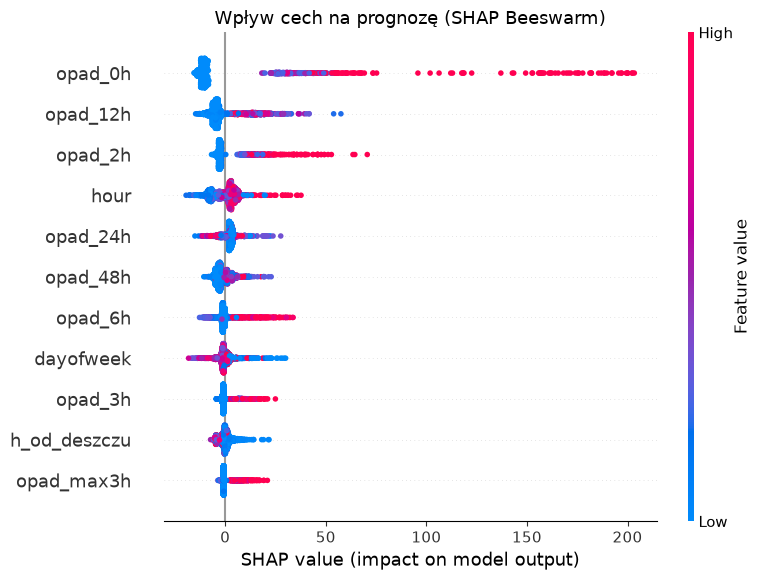

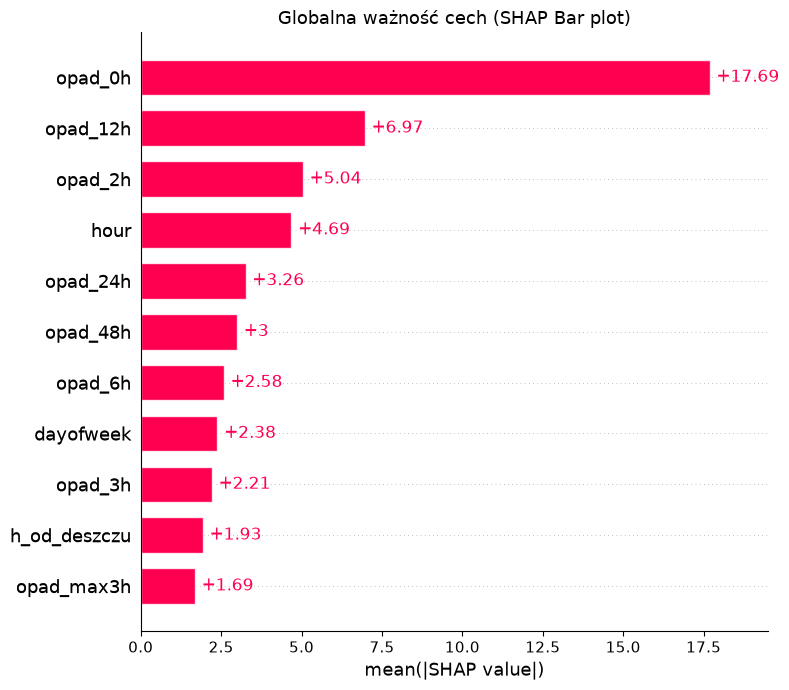

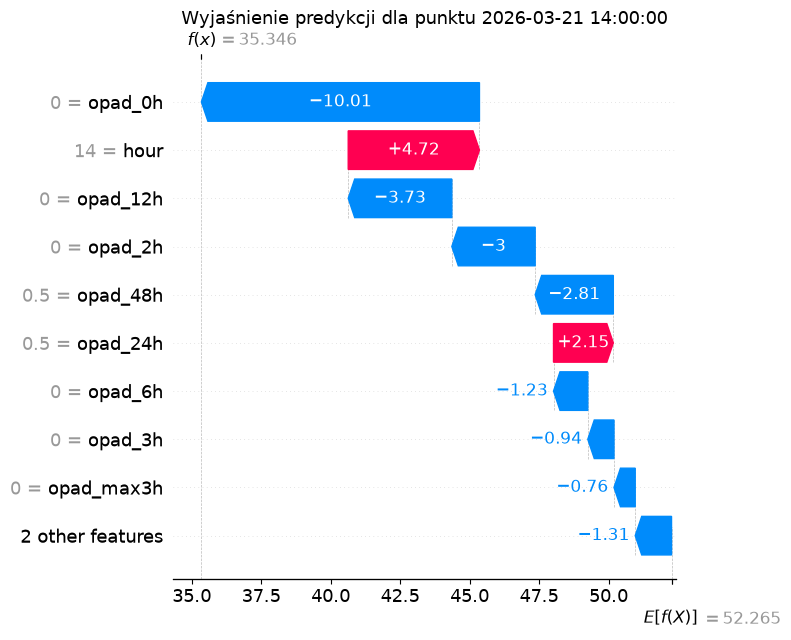

In [12]:
generate_shap_from_tree(lgbm_q,X_val,date_with_time="2026-03-21 14:00:00")

# CATBOOST

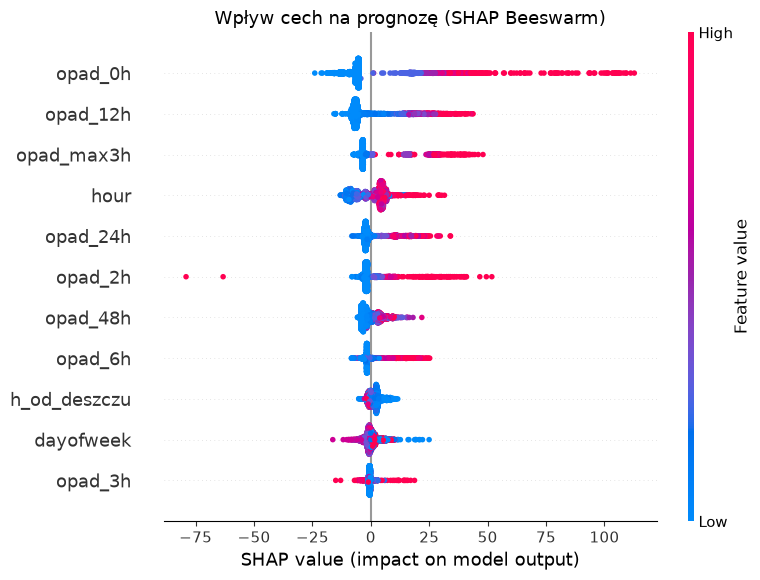

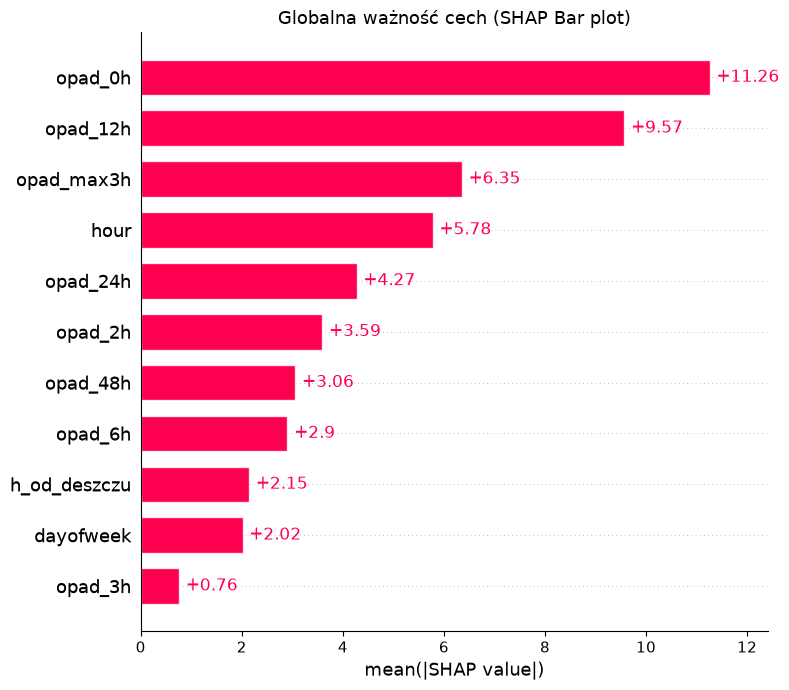

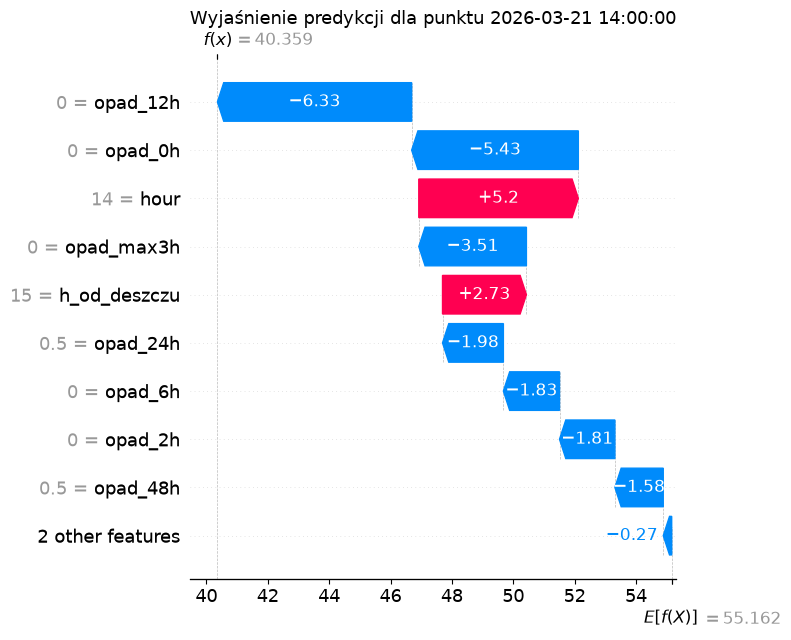

In [13]:
generate_shap_from_tree(cb_q97,X_val,date_with_time="2026-03-21 14:00:00")